# IND320, Assignment 3
## By: Ole Andreas Grøtting
Github: [IND320 - OLEGRO99](https://github.com/olegro99/IND320-OLEGRO99.git)\
Streamlit: https://ind320-olegro99-ybwpxf3ssrwyekrthttcuc.streamlit.app/

## imports

In [71]:
import time
import tomllib
from itertools import product

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from entsoe import EntsoePandasClient

from river import linear_model
from river import preprocessing
from river import optim

from sklearn.metrics import mean_absolute_error, mean_squared_error

# downloading data

In [80]:
def download_exchange_rates(start_date, end_date):

    # Define the Norges Bank API URL for EUR and USD exchange rates against NOK
    url = (
        "https://data.norges-bank.no/api/data/EXR/"
        "B.EUR+USD.NOK.SP"
        f"?format=csv&startPeriod={start_date}"
        f"&endPeriod={end_date}"
        "&locale=en&bom=include"
    )

    # Send a GET request to the API
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Read the CSV response into a pandas DataFrame
    exchange_rates = pd.read_csv(
        pd.io.common.StringIO(response.text),
        sep=";"
    )

    # Return the exchange rate data
    return exchange_rates

In [81]:
# Download EUR and USD exchange rates for the selected period
exchange_rates_df = download_exchange_rates(
    start_date="2024-10-15",
    end_date="2026-10-14"
)

# Display the first rows of the dataset
print(exchange_rates_df.head())

# Display the column names
print(exchange_rates_df.columns)

# Check the number of observations
print("Number of observations:", len(exchange_rates_df))

  FREQ Frequency BASE_CUR Base Currency QUOTE_CUR   Quote Currency TENOR  \
0    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
1    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
2    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
3    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
4    B  Business      USD     US dollar       NOK  Norwegian krone    SP   

  Tenor  DECIMALS  CALCULATED  UNIT_MULT Unit Multiplier COLLECTION  \
0  Spot         4       False          0           Units          C   
1  Spot         4       False          0           Units          C   
2  Spot         4       False          0           Units          C   
3  Spot         4       False          0           Units          C   
4  Spot         4       False          0           Units          C   

              Collection Indicator TIME_PERIOD  OBS_VALUE  
0  ECB concertation time 14:15 CET  2024-10-15    10.791

## checking time zones

In [82]:
def download_nve_data():

    # Define the NVE API URL for reservoir statistics
    url = (
        "https://biapi.nve.no/magasinstatistikk/"
        "api/Magasinstatistikk/HentOffentligData"
    )

    # Send a GET request to the API
    response = requests.get(url, timeout=30)
    response.raise_for_status()

    # Convert the JSON response into a pandas DataFrame
    data = response.json()
    nve_df = pd.DataFrame(data)

    # Remove invalid publication dates
    nve_df = nve_df[
        nve_df["neste_Publiseringsdato"] != "0001-01-01T00:00:00"
    ].copy()

    # Convert the date column to datetime format
    nve_df["dato_Id"] = pd.to_datetime(nve_df["dato_Id"])

    # Return the cleaned reservoir data
    return nve_df


# Download reservoir data from the NVE API
df = download_nve_data()

# Display the first rows of the dataset
print(df.head())

# Summarize observations and date ranges for each reservoir area
print(
    df.groupby(["omrType", "omrnr"])
    .agg(
        observations=("fyllingsgrad", "count"),
        start_date=("dato_Id", "min"),
        end_date=("dato_Id", "max")
    )
)

      dato_Id omrType  omrnr  iso_aar  iso_uke  fyllingsgrad  kapasitet_TWh  \
0  2020-11-15      EL      1     2020       46      0.974361       6.003264   
7  2023-08-13      EL      5     2023       32      0.836849      17.390587   
10 2021-04-18      EL      5     2021       15      0.246682      17.390587   
11 2019-06-02      EL      1     2019       22      0.659981       6.003264   
13 2019-10-27      EL      1     2019       43      0.896057       6.003264   

    fylling_TWh neste_Publiseringsdato  fyllingsgrad_forrige_uke  \
0      5.849344    2020-11-25T13:00:00                  0.997406   
7     14.553301    2023-08-23T13:00:00                  0.776765   
10     4.289936    2021-04-28T13:00:00                  0.276825   
11     3.962040    2019-06-12T13:00:00                  0.625398   
13     5.379270    2019-11-06T13:00:00                  0.882742   

    endring_fyllingsgrad  
0              -0.023046  
7               0.060084  
10             -0.030144  
11      

In [75]:
# Checking timezone for Norges Bank
nb_dates = pd.to_datetime(exchange_rates_df["TIME_PERIOD"])

print(nb_dates.head())
print(nb_dates.dtype)
print(nb_dates.dt.tz)

# Check whether timestamps contain a time component
print(nb_dates.dt.strftime("%Y-%m-%d %H:%M:%S").head())

0   2024-10-15
1   2024-10-16
2   2024-10-17
3   2024-10-18
4   2024-10-21
Name: TIME_PERIOD, dtype: datetime64[us]
datetime64[us]
None
0    2024-10-15 00:00:00
1    2024-10-16 00:00:00
2    2024-10-17 00:00:00
3    2024-10-18 00:00:00
4    2024-10-21 00:00:00
Name: TIME_PERIOD, dtype: str


In [83]:
def download_entsoe_data(start_date, end_date, api_key):

    # Initialize the ENTSO-E API client
    client = EntsoePandasClient(api_key=api_key)

    # Define the start and end dates in UTC
    start = pd.Timestamp(start_date, tz="UTC")
    end = pd.Timestamp(end_date, tz="UTC")

    # Download cross-border electricity flow data from NO_2 to DK_1
    flows = client.query_crossborder_flows(
        country_code_from="NO_2",
        country_code_to="DK_1",
        start=start,
        end=end
    )

    # Convert the returned time series into a DataFrame
    flows_df = flows.rename("flow_mw").to_frame()

    # Return the electricity flow data
    return flows_df


# Load the ENTSO-E API key from secrets.toml
with open("../streamlit app/.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Download cross-border electricity flow data for the selected period
flows_df = download_entsoe_data(
    start_date="2024-10-15",
    end_date="2026-10-15",
    api_key=secrets["ENTSOE_API_KEY"]
)

# Display the first rows and dimensions of the dataset
print(flows_df.head())
print(flows_df.shape)

                           flow_mw
2024-10-15 02:00:00+02:00  1386.84
2024-10-15 03:00:00+02:00  1386.69
2024-10-15 04:00:00+02:00  1386.92
2024-10-15 05:00:00+02:00  1387.20
2024-10-15 06:00:00+02:00  1387.27
(57480, 1)


In [84]:
def download_weather_data(start_date, end_date):

    # Define the Open-Meteo historical weather API URL
    url = "https://archive-api.open-meteo.com/v1/archive"

    # Set the location, date range and weather variables to download
    params = {
        "latitude": 59.66,
        "longitude": 10.78,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": [
            "temperature_2m",
            "precipitation",
            "relative_humidity_2m",
            "wind_speed_10m"
        ],
        "timezone": "GMT"
    }

    # Send a GET request to the API
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    # Convert the JSON response into a pandas DataFrame
    weather_data = response.json()
    weather_df = pd.DataFrame(weather_data["hourly"])

    # Convert timestamps to UTC datetime format
    weather_df["time"] = pd.to_datetime(
        weather_df["time"],
        utc=True
    )

    # Set the timestamp as the DataFrame index
    weather_df = weather_df.set_index("time")

    # Return the weather data
    return weather_df


# Download historical weather data for the selected period
weather_df = download_weather_data(
    start_date="2024-10-15",
    end_date="2026-10-14"
)

# Display the first rows and dimensions of the dataset
print(weather_df.head())
print(weather_df.shape)

                           temperature_2m  precipitation  \
time                                                       
2024-10-15 00:00:00+00:00             1.2            0.0   
2024-10-15 01:00:00+00:00             0.9            0.0   
2024-10-15 02:00:00+00:00             0.5            0.0   
2024-10-15 03:00:00+00:00             0.5            0.0   
2024-10-15 04:00:00+00:00             1.5            0.0   

                           relative_humidity_2m  wind_speed_10m  
time                                                             
2024-10-15 00:00:00+00:00                    86             8.4  
2024-10-15 01:00:00+00:00                    87             7.7  
2024-10-15 02:00:00+00:00                    86             9.1  
2024-10-15 03:00:00+00:00                    85             8.3  
2024-10-15 04:00:00+00:00                    82             5.8  
(17520, 4)


The four data sources have different temporal resolutions. NVE Magasinstatistikk contains multiple observations per date, with weekly intervals between some dates. ENTSO-E mainly provides data at 15-minute intervals, while Open-Meteo provides hourly observations. Norges Bank provides daily exchange rates on business days, resulting in gaps during weekends and holidays.

Regarding time zones, ENTSO-E and Open-Meteo timestamps are represented in UTC. NVE and Norges Bank contain timezone-naive timestamps, meaning that no explicit timezone information is provided. Therefore, the original dates were retained rather than assigning an assumed timezone. This avoids introducing unnecessary timezone conversions.

An initial comparison of ENTSO-E and Open-Meteo timestamps resulted in zero matching timestamps. This was not caused by a timezone difference, but because the datasets covered different periods. ENTSO-E covered October 2024 to October 2026, while the downloaded Open-Meteo data covered 2023.

To combine the data sources, their temporal resolutions must be aligned. ENTSO-E can be aggregated from 15-minute to hourly observations, while Open-Meteo is already hourly. For the forecasting model, the datasets can then be aggregated to monthly frequency. NVE observations can be represented by monthly averages, while Norges Bank exchange rates can also be aggregated to monthly averages.

In [92]:
def prepare_nve_data(nve_df, area_number=1):

    # Select reservoir data for the specified electricity price area
    region_data = nve_df[
        (nve_df["omrType"] == "EL") &
        (nve_df["omrnr"] == area_number)
    ].copy()

    # Aggregate reservoir data into monthly averages
    monthly = (
        region_data
        .set_index("dato_Id")
        [["fyllingsgrad", "fylling_TWh", "kapasitet_TWh"]]
        .resample("MS")
        .mean()
        .dropna()
    )

    # Remove potentially incomplete first and last months
    monthly = monthly.iloc[1:-1].copy()

    # Return the prepared monthly dataset
    return monthly


# Prepare monthly reservoir data for electricity price area NO1
monthly_data = prepare_nve_data(df, area_number=1)

# Display the first rows and dimensions of the dataset
print(monthly_data.head())
print(monthly_data.shape)

            fyllingsgrad  fylling_TWh  kapasitet_TWh
dato_Id                                             
2019-03-01      0.204981     1.230556       6.003264
2019-04-01      0.155148     0.931395       6.003264
2019-05-01      0.452889     2.718814       6.003264
2019-06-01      0.766273     4.600138       6.003264
2019-07-01      0.800576     4.806070       6.003264
(92, 3)


In [93]:
# Aggregate hourly electricity flows into monthly averages
entsoe_monthly = (
    flows_df
    .resample("MS")
    .mean()
)

# Remove timezone information after aggregation in UTC
entsoe_monthly.index = entsoe_monthly.index.tz_localize(None)

In [95]:
# Aggregate hourly weather data into monthly values
weather_monthly = weather_df.resample("MS").agg({
    "temperature_2m": "mean",
    "precipitation": "sum",
    "relative_humidity_2m": "mean",
    "wind_speed_10m": "mean"
})

# Remove timezone information after aggregation in UTC
weather_monthly.index = weather_monthly.index.tz_localize(None)

print(exchange_rates_df.columns.tolist())
print(exchange_rates_df.head())

['FREQ', 'Frequency', 'BASE_CUR', 'Base Currency', 'QUOTE_CUR', 'Quote Currency', 'TENOR', 'Tenor', 'DECIMALS', 'CALCULATED', 'UNIT_MULT', 'Unit Multiplier', 'COLLECTION', 'Collection Indicator', 'TIME_PERIOD', 'OBS_VALUE']
  FREQ Frequency BASE_CUR Base Currency QUOTE_CUR   Quote Currency TENOR  \
0    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
1    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
2    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
3    B  Business      USD     US dollar       NOK  Norwegian krone    SP   
4    B  Business      USD     US dollar       NOK  Norwegian krone    SP   

  Tenor  DECIMALS  CALCULATED  UNIT_MULT Unit Multiplier COLLECTION  \
0  Spot         4       False          0           Units          C   
1  Spot         4       False          0           Units          C   
2  Spot         4       False          0           Units          C   
3  Spot         4       False      

In [96]:
# Create an overview of time zones before and after monthly aggregation
timezone_overview = pd.DataFrame({
    "Data source": [
        "NVE",
        "ENTSO-E",
        "Open-Meteo",
        "Norges Bank"
    ],
    "Original timezone": [
        str(df["dato_Id"].dt.tz),  # Time zone of the original NVE timestamps
        str(flows_df.index.tz),  # Time zone of the original ENTSO-E timestamps
        str(weather_df.index.tz),  # Time zone of the original Open-Meteo timestamps
        str(pd.to_datetime(exchange_rates_df["TIME_PERIOD"]).dt.tz)  # Time zone of the original exchange rate timestamps
    ],
    "Monthly timezone": [
        str(monthly_data.index.tz),  # Time zone after monthly aggregation
        str(entsoe_monthly.index.tz),  # Time zone after monthly aggregation
        str(weather_monthly.index.tz),  # Time zone after monthly aggregation
        "Not yet aggregated"  # Norges Bank data has not been aggregated yet
    ]
})

# Display the time zone overview
print(timezone_overview)

   Data source Original timezone    Monthly timezone
0          NVE              None                None
1      ENTSO-E       Europe/Oslo                None
2   Open-Meteo               UTC                None
3  Norges Bank              None  Not yet aggregated


In [97]:
# Combine the monthly datasets using their common dates
combined_data = (
    monthly_data
    .join(weather_monthly, how="inner")  # Join NVE and weather data using matching dates
    .join(entsoe_monthly, how="inner")  # Add ENTSO-E data using matching dates
)

# Keep only complete months within the selected study period
combined_data = combined_data.loc[
    "2024-11-01":"2026-09-01"  # Select months from November 2024 to September 2026
].dropna()  # Remove rows containing missing values

# Display information about the combined dataset
print("Number of observations:", len(combined_data))  # Number of complete monthly observations
print("Start:", combined_data.index.min())  # First month in the dataset
print("End:", combined_data.index.max())  # Last month in the dataset
print(combined_data.head())  # Display the first five observations
print(combined_data.isna().sum())  # Check for missing values in each column

Number of observations: 23
Start: 2024-11-01 00:00:00
End: 2026-09-01 00:00:00
            fyllingsgrad  fylling_TWh  kapasitet_TWh  temperature_2m  \
dato_Id                                                                
2024-11-01      0.924905     5.552451       6.003264        1.992500   
2024-12-01      0.803228     4.821990       6.003264        0.355645   
2025-01-01      0.663941     3.985812       6.003264       -3.171909   
2025-02-01      0.486722     2.921918       6.003264       -2.794643   
2025-03-01      0.320056     1.921381       6.003264        3.336559   

            precipitation  relative_humidity_2m  wind_speed_10m      flow_mw  
dato_Id                                                                       
2024-11-01           35.2             84.518056        9.362083  1085.276403  
2024-12-01           64.5             87.009409       11.639382  1035.045941  
2025-01-01          110.4             88.946237        9.851747  1022.086841  
2025-02-01           

The four data sources have different temporal resolutions. NVE Magasinstatistikk contains multiple observations per date, with weekly intervals between some dates. ENTSO-E mainly provides data at 15-minute intervals, while Open-Meteo provides hourly observations. Norges Bank provides daily exchange rates on business days, resulting in gaps during weekends and holidays.

Regarding time zones, ENTSO-E and Open-Meteo timestamps are represented in UTC. NVE and Norges Bank contain timezone-naive timestamps, meaning that no explicit timezone information is provided. Therefore, the original dates were retained rather than assigning an assumed timezone. This avoids introducing unnecessary timezone conversions. Since ENTSO-E and Open-Meteo are the main sources of hourly data, ensuring consistency between their UTC timestamps is particularly important.

To combine the data sources, their temporal resolutions must be aligned. ENTSO-E can be aggregated from 15-minute to hourly observations, while Open-Meteo is already hourly. For the forecasting model, the datasets can then be aggregated to monthly frequency. NVE observations can be represented by monthly averages, while Norges Bank exchange rates can also be aggregated to monthly averages.

## machine learning - preprocessing

In [99]:
def forecast_reservoir(
    reservoir_data,
    target_col="fyllingsgrad",
    history_length=60,
    horizon=6,
    n_lags=6,
    learning_rate=0.001
):
    start_time = time.time()  # Start measuring execution time

    # Prepare monthly target data
    data = reservoir_data[[target_col]].copy()  # Select the target variable
    data.index = pd.to_datetime(data.index)  # Ensure the index uses datetime format

    data[target_col] = pd.to_numeric(
        data[target_col],
        errors="coerce"
    )  # Convert target values to numeric and replace invalid values with NaN

    data = (
        data
        .sort_index()  # Sort observations chronologically
        .resample("MS")  # Aggregate observations by month, starting at month start
        .mean()  # Calculate the monthly average
        .dropna()  # Remove months with missing target values
    )

    values = data[target_col].to_numpy()  # Extract target values as a NumPy array

    if len(values) < history_length:
        raise ValueError("Not enough historical observations.")  # Check that enough historical data is available

    if n_lags >= history_length:
        raise ValueError("n_lags must be smaller than history_length.")  # Ensure the lag window is smaller than the history window

    if horizon < 1:
        raise ValueError("horizon must be at least 1.")  # Ensure the forecast horizon is positive

    upper_limit = 1 if values.max() <= 1.5 else 100  # Set the maximum value depending on whether filling is expressed as a fraction or percentage

    # Initialize the River model
    model = (
        preprocessing.StandardScaler()
        |
        linear_model.LinearRegression(
            optimizer=optim.SGD(lr=learning_rate)
        )
    )

    # Create lag and seasonal features
    def make_features(history, date):

        features = {}

        for lag in range(1, n_lags + 1):
            features[f"lag_{lag}"] = history[-lag]  # Add previous observations as lag features

        month = date.month  # Extract the month from the forecast date

        features["month_sin"] = np.sin(
            2 * np.pi * month / 12
        )  # Encode the month using a sine transformation

        features["month_cos"] = np.cos(
            2 * np.pi * month / 12
        )  # Encode the month using a cosine transformation

        return features  # Return the feature dictionary

    # Train using the selected history window
    training_start = len(values) - history_length  # Determine where the training window begins

    for i in range(training_start + n_lags, len(values)):

        history = values[i - n_lags:i]  # Select the previous observations for training

        features = make_features(
            history,
            data.index[i]
        )  # Generate lag and seasonal features for the current observation

        model.learn_one(features, values[i])  # Update the model using the current observation and its actual target value

    # Recursive forecasting
    target_history = list(values)  # Initialize history with all available observations
    predictions = []

    last_date = data.index[-1]  # Identify the date of the latest observation

    for step in range(1, horizon + 1):

        future_date = last_date + pd.DateOffset(months=step)  # Calculate the next forecast month

        features = make_features(
            target_history,
            future_date
        )  # Generate features using the latest available history

        prediction = model.predict_one(features)  # Predict the reservoir filling level

        prediction = np.clip(
            prediction,
            0,
            upper_limit
        )  # Restrict predictions to valid filling levels

        predictions.append({
            "date": future_date,
            "predicted_filling": prediction
        })  # Store the forecast date and predicted filling level

        target_history.append(prediction)  # Add the prediction to history for the next forecast step

    forecast_df = pd.DataFrame(predictions)  # Convert predictions into a DataFrame

    forecast_df.attrs["runtime_seconds"] = (
        time.time() - start_time
    )  # Store the total execution time

    return forecast_df  # Return the forecast results

## testing the function

In [25]:
# Generate forecast for the next 6 months
forecast = forecast_reservoir(
    reservoir_data=monthly_data,
    history_length=48,
    horizon=6,
    n_lags=6,
    learning_rate=0.01
)

# Display predictions
print(forecast)

# Display runtime
print(
    f"Runtime: {forecast.attrs['runtime_seconds']:.4f} seconds"
)

        date  predicted_filling
0 2026-10-01           0.612950
1 2026-11-01           0.482078
2 2026-12-01           0.343529
3 2027-01-01           0.251118
4 2027-02-01           0.189656
5 2027-03-01           0.174014
Runtime: 0.0084 seconds


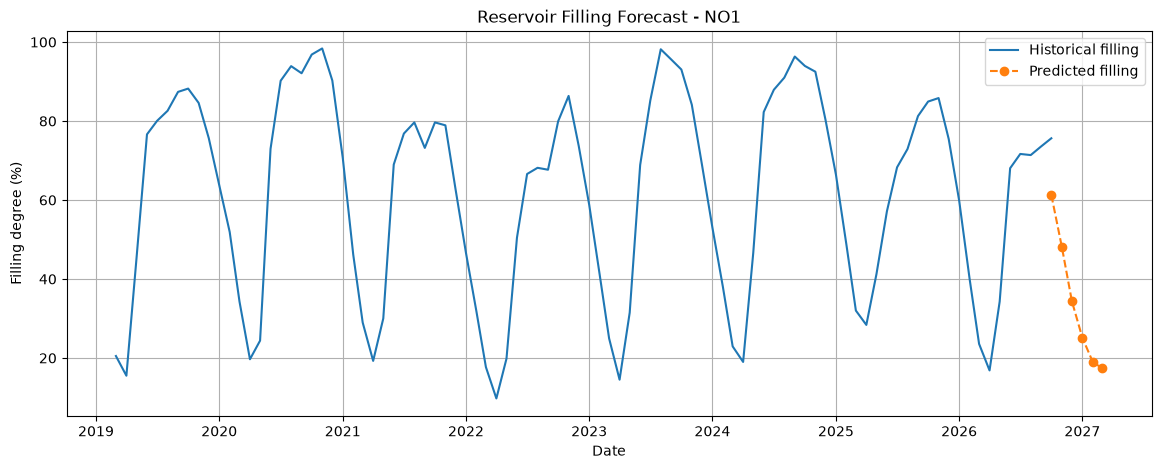

In [102]:
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_data.index,
    monthly_data["fyllingsgrad"] * 100,
    label="Historical filling"
)

plt.plot(
    forecast["date"],
    forecast["predicted_filling"] * 100,
    marker="o",
    linestyle="--",
    label="Predicted filling"
)

plt.title("Reservoir Filling Forecast - NO1")
plt.xlabel("Date")
plt.ylabel("Filling degree (%)")

plt.legend()
plt.grid()
plt.show()

In [100]:
def backtest_reservoir(
    data,
    target_col="fyllingsgrad",
    history_length=60,
    horizon=6,
    n_lags=6,
    learning_rate=0.001,
    first_origin=None,
    step=1
):

    # Prepare and aggregate the reservoir data
    data = data[[target_col]].copy().sort_index()  # Select the target variable and sort observations chronologically
    data = data.resample("MS").mean().dropna()  # Aggregate observations into monthly averages and remove missing values

    if first_origin is None:
        first_origin = history_length + 1  # Set the first forecast origin after the initial training period

    results = []

    # Perform rolling-origin backtesting
    for origin in range(
        first_origin,
        len(data) - horizon + 1,
        step
    ):

        train_data = data.iloc[:origin]  # Use all observations up to the current forecast origin

        actual = data[target_col].iloc[
            origin:origin + horizon
        ]  # Select the actual values for the forecast horizon

        # Generate forecasts using the training data
        prediction = forecast_reservoir(
            reservoir_data=train_data,
            target_col=target_col,
            history_length=history_length,
            horizon=horizon,
            n_lags=n_lags,
            learning_rate=learning_rate
        )

        baseline = train_data[target_col].iloc[-1]  # Use the latest observed value as a baseline forecast

        # Store actual values, predictions and baseline forecasts
        for j in range(horizon):

            results.append({
                "forecast_origin": train_data.index[-1],  # Date when the forecast is made
                "date": actual.index[j],  # Date of the forecasted observation
                "horizon_step": j + 1,  # Forecasting step (1 to horizon)
                "actual": actual.iloc[j],  # Actual reservoir filling level
                "predicted": prediction["predicted_filling"].iloc[j],  # Model prediction
                "baseline": baseline  # Baseline prediction using the latest observed value
            })

    results_df = pd.DataFrame(results)  # Convert collected forecasts into a DataFrame

    if results_df.empty:
        raise ValueError("Not enough data for backtesting.")  # Check that enough observations are available

    # Calculate model performance metrics
    y_true = results_df["actual"]  # Actual reservoir filling levels
    y_pred = results_df["predicted"]  # Model predictions
    y_base = results_df["baseline"]  # Baseline predictions

    metrics = pd.DataFrame({
        "Model": {
            "MAE": mean_absolute_error(y_true, y_pred),  # Calculate mean absolute error for the model
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))  # Calculate root mean squared error for the model
        },
        "Baseline": {
            "MAE": mean_absolute_error(y_true, y_base),  # Calculate mean absolute error for the baseline
            "RMSE": np.sqrt(mean_squared_error(y_true, y_base))  # Calculate root mean squared error for the baseline
        }
    })

    return results_df, metrics  # Return individual forecasts and the performance comparison

In [101]:
# Define parameter values to test
history_lengths = [24, 36, 48, 60]  # Number of historical months used for training
n_lags_values = [3, 6, 12]  # Number of previous observations used as input features
learning_rates = [0.001, 0.01, 0.1]  # Learning rates for the stochastic gradient descent optimizer

horizon = 6  # Forecast six months ahead

# Use the same forecast origins for all parameter combinations
common_first_origin = max(history_lengths) + 1  # Start backtesting after the longest initial training period

results = []

# Test all combinations of hyperparameters
for history, lags, lr in product(
    history_lengths,
    n_lags_values,
    learning_rates
):

    if lags >= history:
        continue  # Skip combinations where the number of lags is too large

    # Run backtesting with the current parameter combination
    backtest_results, metrics = backtest_reservoir(
        data=monthly_data,
        history_length=history,
        horizon=horizon,
        n_lags=lags,
        learning_rate=lr,
        first_origin=common_first_origin
    )

    # Store model performance and parameter values
    results.append({
        "history_length": history,
        "n_lags": lags,
        "learning_rate": lr,
        "MAE": metrics.loc["MAE", "Model"],  # Model mean absolute error
        "RMSE": metrics.loc["RMSE", "Model"],  # Model root mean squared error
        "Baseline_MAE": metrics.loc["MAE", "Baseline"],  # Baseline mean absolute error
        "Baseline_RMSE": metrics.loc["RMSE", "Baseline"]  # Baseline root mean squared error
    })

# Sort parameter combinations by MAE, with the best-performing model first
parameter_results = (
    pd.DataFrame(results)
    .sort_values("MAE")
)

# Display the parameter comparison
print(parameter_results)

    history_length  n_lags  learning_rate       MAE      RMSE  Baseline_MAE  \
30              60       6          0.001  0.257597  0.296960      0.300048   
27              60       3          0.001  0.275534  0.320702      0.300048   
21              48       6          0.001  0.313416  0.359052      0.300048   
33              60      12          0.001  0.314413  0.351931      0.300048   
18              48       3          0.001  0.321870  0.373303      0.300048   
28              60       3          0.010  0.340028  0.367053      0.300048   
31              60       6          0.010  0.345564  0.384442      0.300048   
12              36       6          0.001  0.365858  0.418724      0.300048   
9               36       3          0.001  0.377324  0.432323      0.300048   
24              48      12          0.001  0.378390  0.422008      0.300048   
4               24       6          0.010  0.419451  0.471764      0.300048   
34              60      12          0.010  0.430723 

Several parameter combinations were tested, and the best results were achieved with a history length of 60 months, 6 lags, a learning rate of 0.001 and a forecast horizon of 6 months. The model achieved an MAE of 0.2544 and an RMSE of 0.2944, outperforming the simple baseline model.

In [103]:
# Run backtesting using the selected model parameters
backtest_results, metrics = backtest_reservoir(
    data=monthly_data,       # Historical monthly reservoir data
    history_length=60,       # Number of months used for model training
    horizon=6,               # Number of months to forecast
    n_lags=6,                # Number of previous observations used as features
    learning_rate=0.001       # Learning rate for the online learning algorithm
)

# Display the evaluation metrics (MAE and RMSE) for the model and baseline
print(metrics)

         Model  Baseline
MAE   0.257597  0.300048
RMSE  0.296960  0.365553


In [104]:

# Group the backtesting results by forecast horizon
# This allows us to evaluate model performance for each prediction month
horizon_metrics = backtest_results.groupby(
    "horizon_step"
).apply(
    lambda x: pd.Series({
        # Calculate the Mean Absolute Error for each forecast horizon
        "MAE": np.mean(
            np.abs(x["actual"] - x["predicted"])
        ),

        # Calculate the Root Mean Squared Error for each forecast horizon
        "RMSE": np.sqrt(
            np.mean(
                (x["actual"] - x["predicted"]) ** 2
            )
        )
    })
)

# Display the evaluation metrics for each forecast horizon
print(horizon_metrics)


                   MAE      RMSE
horizon_step                    
1             0.230479  0.267543
2             0.254190  0.295375
3             0.272903  0.313317
4             0.269670  0.309861
5             0.262708  0.300975
6             0.255634  0.292434


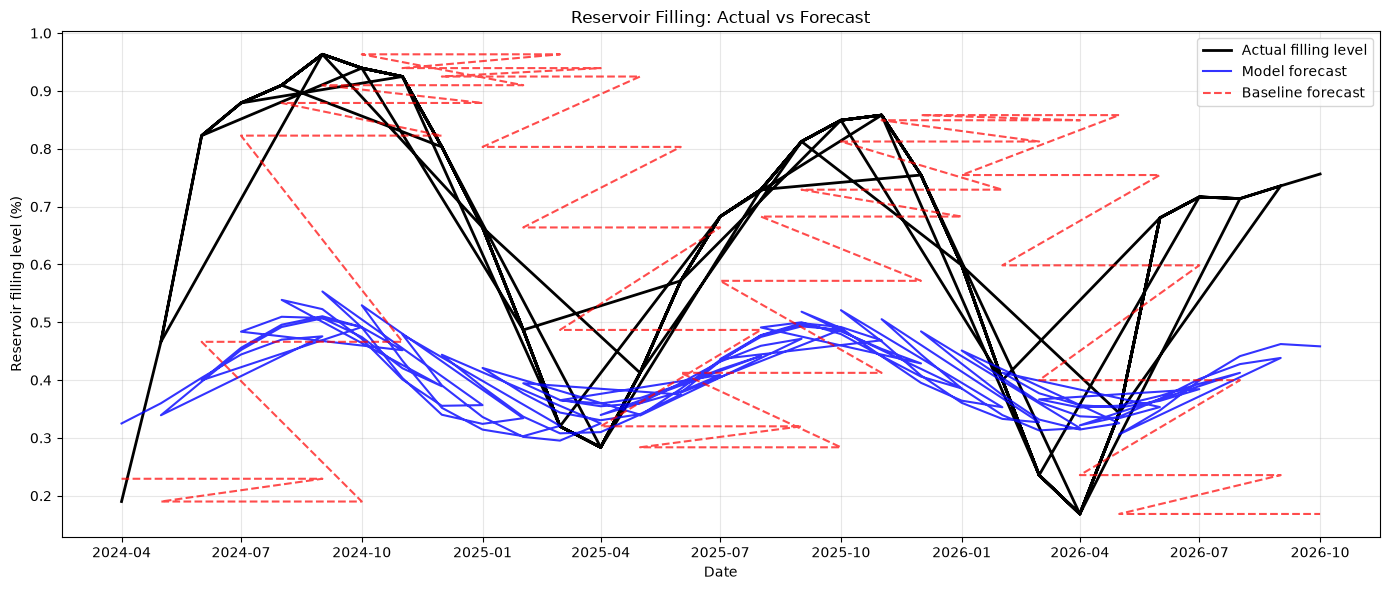

In [106]:
import matplotlib.pyplot as plt

# Select the best-performing parameter combination
best_params = parameter_results.iloc[0]

# Run backtesting using the best parameters
best_backtest, best_metrics = backtest_reservoir(
    data=monthly_data,
    history_length=int(best_params["history_length"]),
    horizon=horizon,
    n_lags=int(best_params["n_lags"]),
    learning_rate=best_params["learning_rate"],
    first_origin=common_first_origin
)

# Plot actual values and forecasts
plt.figure(figsize=(14, 6))

plt.plot(
    best_backtest["date"],
    best_backtest["actual"],
    label="Actual filling level",
    color="black",
    linewidth=2
)

plt.plot(
    best_backtest["date"],
    best_backtest["predicted"],
    label="Model forecast",
    color="blue",
    alpha=0.8
)

plt.plot(
    best_backtest["date"],
    best_backtest["baseline"],
    label="Baseline forecast",
    color="red",
    linestyle="--",
    alpha=0.7
)

plt.xlabel("Date")
plt.ylabel("Reservoir filling level (%)")
plt.title("Reservoir Filling: Actual vs Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

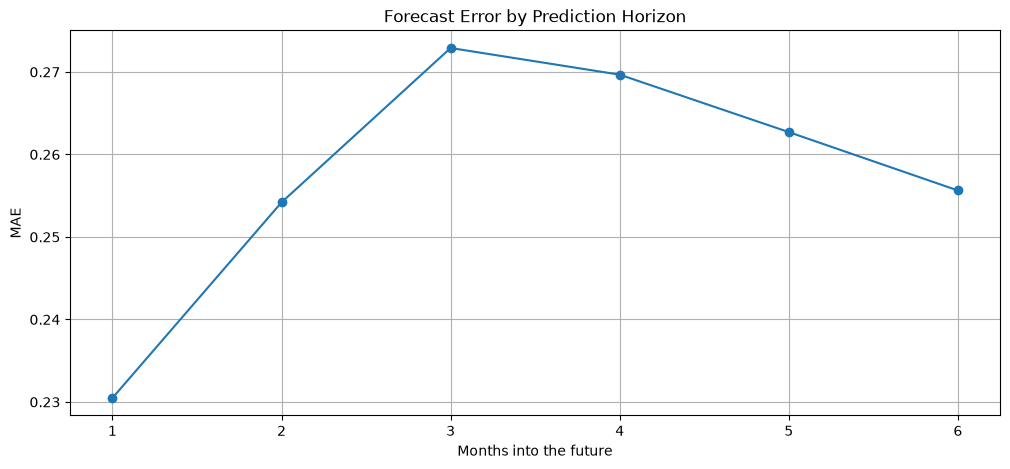

In [105]:

# Create a figure to visualize forecast errors across different horizons
plt.figure(figsize=(12, 5))

# Plot MAE for each forecast horizon
plt.plot(
    horizon_metrics.index,
    horizon_metrics["MAE"],
    marker="o"
)

# Add title and axis labels
plt.title("Forecast Error by Prediction Horizon")
plt.xlabel("Months into the future")
plt.ylabel("MAE")

# Set x-axis ticks to represent the six forecast months
plt.xticks(range(1, 7))

# Add grid lines and display the plot
plt.grid()
plt.show()
